In [4]:
# Setup module

# Load packages
import QuantLib as ql
import pandas as pd
import matplotlib.pyplot as plt
import datetime as dt
import sys
from IPython.display import display
from pathlib import Path

In [5]:
# Load data
# Find the repository root
def find_repo_root():
    path = Path.cwd().resolve()

    for parent in [path, *path.parents]:
        if (parent / "requirements.txt").exists():
            return parent

    raise FileNotFoundError(
        "Repository root could not be found. "
        "Make sure you are running this notebook from within the repository."
    )


# Define repository paths
repo_root = find_repo_root()
data_directory = repo_root / "data"

euribor_file = data_directory / "6M EURIBOR 20260820.xlsx"
ESTR_file = data_directory / "ESTR 20260820.xlsx"

ESTR_data = pd.read_excel(
    ESTR_file,
    sheet_name="Data",
    skiprows=0
)

Euribor_data = pd.read_excel(
    euribor_file,
    sheet_name="Data",
    skiprows=0
)

# Load Euribor fixing data from data folder
Euribor6M_fixings_file = data_directory / "EUR006 Index 20260212-20260820.xlsx"
Euribor6M_fixings = pd.read_excel(Euribor6M_fixings_file)

# Add the QuantLib date as column to the data
Euribor6M_fixings['AsOfDate'] = Euribor6M_fixings.apply(
    lambda row: ql.Date(
        int(row['Day']),
        int(row['Month']),
        int(row['Year'])
    ),
    axis=1
)

# Set the QuantLib evaluation date
ql.Settings.instance().evaluationDate = ql.Date(20, 8, 2026)

# Bootstrap the ESTR curve -> code contained in setup file
setup_directory = repo_root / "courses" / "setup"
%run "$setup_directory/setup4.py"

ql.Settings.instance().enforcesTodaysHistoricFixings = False  # Use forecast if fixing is unavailable
ql.IndexManager.instance().clearHistories()

ESTR curve constructed and ready to use. Setup complete


# 1. Introduction to Euribor and Euribor swaps
Euribor is short for Euro Interbank Offered Rate. The Euribor rates are based on the average interest rates at which a large panel of European banks borrow funds from one another. The rates are available for different maturities, ranging from one week to one year (https://www.euribor-rates.eu/en/). 

Just like the ESTR rates, Euribor rates are widely used amongst market participants. The key difference between Euribor and ESTR is that Euribor contains term and bank credit risk:
- term risk: where ESTR rates were overnight rates, Euribor rates have maturities up to one year. Within that year, interest rates in general can rise, which implies you could get a higher compensation for a new loan. This introduces term risk. 
- bank credit risk: throughout the year, the creditworthiness of the banks involved with the loan can decrease. This introduces credit risk. For ESTR, this risk is minimal, as you're only lending your money overnight. 

Before the banking crisis of 2008, Euribor was considered as the main risk free rate and was used for pricing financial instruments. After the banking crisis, the credit risk component implied that Euribor was no longer considered as risk free, and market participants started to use overnight rates as risk free rates for instrument pricing. First, this was EONIA, and later this was ESTR for discounting and collateralized derivatives. 

# 2. Euribor index in QuantLib
QuantLib provides predefined index objects that can represent indices such as the 6-month Euribor. Let's create such an index and have a look at it's default settings.

In [6]:
Euribor6M_curve_handle   = ql.RelinkableYieldTermStructureHandle() # an empty curve handle that will be linked to the 6-month euribor curve later
Euribor6M_index = ql.Euribor6M(Euribor6M_curve_handle)

print(f"""
name():           {Euribor6M_index.name()}
fixingCalendar(): {Euribor6M_index.fixingCalendar()}
dayCounter():     {Euribor6M_index.dayCounter()}
currency()        {Euribor6M_index.currency()}
hasFixing()       {Euribor6M_index.hasHistoricalFixing(ql.Date(1,1,2027))}
""")


name():           Euribor6M Actual/360
fixingCalendar(): TARGET calendar
dayCounter():     Actual/360 day counter
currency()        European Euro
hasFixing()       False



Just like the ESTR index object, the advantage of the Euribor index in QuantLib is that it already sets some of the parameters to the correct values, such as the fixing calendar and the currency. These values are predefined in the ql.Euribor6M() index constructor function.

## 3. Introduction to 6M-Euribor swaps
An Euribor swap is a contract between two parties to exchange a fixed interest rate for a floating interest rate linked to the 6M-Euribor index. One party pays a fixed rate throughout the life of the swap, while the other pays the realised compounded 6M-Euribor rate. 

In [7]:
display(Euribor_data)

,Term,Market Rate,Year Fraction
0,6 MO,2.74,0.5
1,1 YR,2.95,1.0
2,18 MO,3.02,1.5
3,2 YR,3.05,2.0
4,3 YR,3.07,3.0
5,4 YR,3.09,4.0
6,5 YR,3.11,5.0
7,6 YR,3.14,6.0
8,7 YR,3.17,7.0
9,8 YR,3.20,8.0


# 6M-Euribor curve construction

In [8]:
# Helpers
Euribor6M_quotes = []
Euribor6M_helpers = ql.RateHelperVector()

# Deposit rate helper takes todays Euribor 6m fixing
current_Euribor6M_fixing = Euribor_data.loc[0, 'Market Rate']/100                 # pass the fixing as a numeric, not as percentage
current_Euribor6M_fixing_quote = ql.SimpleQuote(current_Euribor6M_fixing)         # wrap the quote in a simple quote object
current_Euribor6M_fixing_handle = ql.QuoteHandle(current_Euribor6M_fixing_quote)  # wrap the quote in a handle

Euribor6M_quotes.append(current_Euribor6M_fixing_quote)                                # add fixing to the list of quotes

deposit_helper = ql.DepositRateHelper(
        current_Euribor6M_fixing_handle, 
        Euribor6M_index # Euribor index object
    )
Euribor6M_helpers.append(deposit_helper)

print(f'Created a deposit rate helper with rate: {round(deposit_helper.quote().value()*100, 2)}% and maturity date {deposit_helper.maturityDate()}')


Created a deposit rate helper with rate: 2.74% and maturity date February 24th, 2027


In [9]:
# Set parameters that are the same for all swap helpers
calendar           = ql.TARGET()                                # the Calendar used for coupon date construction
settlementDays     = 2                                          # the number of days between entering the swap and starting the coupon accrual period
fixedLegFrequency  = ql.Annual                                  # the payment frequency for the fixed leg
fixedLegConvention = ql.ModifiedFollowing                       # the convention how to handle non-business days
fixedLegDayCount   = ql.Thirty360(ql.Thirty360.BondBasis)       # the daycount used compute interest accrual
floatLegSpread     = ql.QuoteHandle(ql.SimpleQuote(0.0))        # sometimes swaps have a preset spread, but we'll not use this and set it to zero
forwardStartPeriod = ql.Period(0, ql.Days)                      # in case of a forward staring swap, this should be changed. But we'll keep it to zero


for idx, row in Euribor_data.iloc[1:].iterrows():
    # Tenor: extract the tenor and convert it to a QuantLib period such that it can be used in constructing the swap helper
    [tenor_numeric, period] = row['Term'].split()
    tenor_numeric = int(tenor_numeric)
    if period == "WK":
        tenor = ql.Period(tenor_numeric, ql.Weeks)
    elif period == "MO": 
        tenor = ql.Period(tenor_numeric, ql.Months)
    elif period == "YR":
        tenor = ql.Period(tenor_numeric, ql.Years)
    else:
        raise ValueError(f"{row['Term']} not specified")

    # Quote handle
    quote = float(row['Market Rate']) / 100
    quote_object = ql.SimpleQuote(quote)
    quote_handle = ql.QuoteHandle(quote_object)

    # Create a swap helper:
    swap_helper = ql.SwapRateHelper(
        quote_handle,
        tenor,
        calendar, 
        fixedLegFrequency,
        fixedLegConvention,
        fixedLegDayCount,
        Euribor6M_index, # index linked to Euribor 6m curve used for projecting floating leg cash flows
        floatLegSpread,
        forwardStartPeriod,
        ESTR_curve_handle # discount curve to compute PV of fixed & floating leg --> ESTR means dual discounting
    )
    Euribor6M_helpers.append(swap_helper)

In [10]:
curveDate = ql.Settings.instance().evaluationDate

Euribor6M_curve = ql.PiecewiseLogCubicDiscount(
    curveDate,
    Euribor6M_helpers,
    ql.Actual365Fixed()
)

Euribor6M_curve.enableExtrapolation()

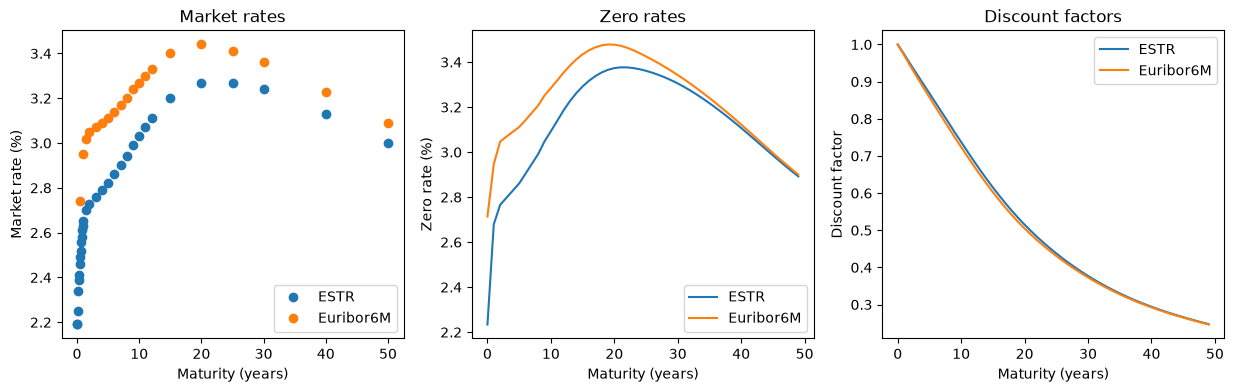

In [11]:
# Create the plot figure
fig, axes = plt.subplots(nrows=1,ncols=3, figsize=(15,4))

# Plot the market rates directly from the data
axes[0].plot(ESTR_data['Year Fraction'], ESTR_data['Market Rate'], marker='o', linestyle='', label='ESTR')
axes[0].plot(Euribor_data['Year Fraction'], Euribor_data['Market Rate'], marker='o', linestyle='', label='Euribor6M')

# Plot the zero rates
max_maturity = int(max(ESTR_data['Year Fraction']))
x_values = range(max_maturity)
axes[1].plot(x_values, [ESTR_curve.zeroRate(x, ql.Compounded, ql.Annual).rate() * 100 for x in range(max_maturity)], label='ESTR')
axes[1].plot(x_values, [Euribor6M_curve.zeroRate(x, ql.Compounded, ql.Annual).rate() * 100 for x in range(max_maturity)], label='Euribor6M')

# Plot the discount factors, use max_maturity from the zero rates
axes[2].plot(x_values, [ESTR_curve.discount(x) for x in range(max_maturity)], label='ESTR')
axes[2].plot(x_values, [Euribor6M_curve.discount(x) for x in range(max_maturity)], label='Euribor6M')

# Finish the plot by setting titles and axis titles
axes[0].set_title('Market rates')
axes[1].set_title('Zero rates')
axes[2].set_title('Discount factors')

axes[0].set_xlabel('Maturity (years)')
axes[0].set_ylabel('Market rate (%)')
axes[1].set_xlabel('Maturity (years)')
axes[1].set_ylabel('Zero rate (%)')
axes[2].set_xlabel('Maturity (years)')
axes[2].set_ylabel('Discount factor')

axes[0].legend(); axes[1].legend(); axes[2].legend()

# Euribor swap pricing

In [12]:
calendar = ql.TARGET()
issueDate = ql.Date(12,2,2026)                                                                      # the issuedate of the swap
unadjustedMaturityDate   = calendar.advance(issueDate, 10, ql.Years, ql.Unadjusted)                 # the unadjusted maturity date according to the calendar TARGET()
fixedLegPaymentFrequency = ql.Period(ql.Annual)                                                     # fixed leg makes annual payments
fixedLegConvention = ql.ModifiedFollowing                                                           # this parameter defines what happens when a cash flow falls on a non-business day: we pick the following business day
dateGeneration = ql.DateGeneration.Backward                                                         # this parameter defines how to generate the coupon dates from the issue- and maturity date. Backward means starting at the unadjusted maturity date and filling the dates backward.
endOfMonth = False

# Fixed leg payment schedule
fixedSchedule = ql.Schedule(
    issueDate,
    unadjustedMaturityDate, # use the unadjusted maturity date
    fixedLegPaymentFrequency,
    Euribor6M_index.fixingCalendar(),
    fixedLegConvention,
    fixedLegConvention,
    dateGeneration,
    endOfMonth
)

# Floating leg payment schedule
floatSchedule = ql.Schedule(
    issueDate,
    unadjustedMaturityDate,
    Euribor6M_index.tenor(), # payment frequency floating leg extracted from index (6m euribor = semiannually)
    Euribor6M_index.fixingCalendar(), # calendar extracted from fixing
    Euribor6M_index.businessDayConvention(), # floatLeg business day convention extracted from index
    Euribor6M_index.businessDayConvention(), # floatLeg business day convention extracted from index
    dateGeneration, # floatLeg date generation
    endOfMonth
)

# parameters
notional = 10e6
fixedRate = 0.03
fixedLegDayCount = ql.Thirty360(ql.Thirty360.USA)

Euribor6M_swap = ql.VanillaSwap(
    ql.VanillaSwap.Receiver, # receiver swap
    notional,
    fixedSchedule,
    fixedRate, # murex rate
    fixedLegDayCount,
    floatSchedule,
    Euribor6M_index,
    0,
    Euribor6M_index.dayCounter()
)

In [13]:
# Create a handle to your discounting curve
discounting_curve_handle = ql.RelinkableYieldTermStructureHandle()              # empty handle, doesn't point to any curve yet

# Create a discounting bond engine
discounting_swap_engine = ql.DiscountingSwapEngine(discounting_curve_handle)    # pricing engine linked to a curve handle

# Connect the engine to your bond
Euribor6M_swap.setPricingEngine(discounting_swap_engine)                        # set the pricing engine of your bond

# Select a curve as discount curve and link your handle
discounting_curve_handle.linkTo(ESTR_curve)                                     # link your discount handle to the ESTR curve such that you use the ESTR curve for discounting
Euribor6M_curve_handle.linkTo(Euribor6M_curve)

In [16]:
ql.IndexManager.instance().clearHistories()
display(Euribor6M_fixings)
for idx, row in Euribor6M_fixings.iterrows():
    if pd.notna(row['Index values']):
        Euribor6M_index.addFixing(row['AsOfDate'], row['Index values'])


,Date,Index values,Day,Month,Year,AsOfDate
0,2026-02-12,2.131,12,2,2026,"February 12th, 2026"
1,2026-02-13,2.147,13,2,2026,"February 13th, 2026"
2,2026-02-14,NaN,14,2,2026,"February 14th, 2026"
3,2026-02-15,NaN,15,2,2026,"February 15th, 2026"
4,2026-02-16,2.155,16,2,2026,"February 16th, 2026"
...,...,...,...,...,...,...
185,2026-08-16,NaN,16,8,2026,"August 16th, 2026"
186,2026-08-17,2.687,17,8,2026,"August 17th, 2026"
187,2026-08-18,2.697,18,8,2026,"August 18th, 2026"
188,2026-08-19,2.719,19,8,2026,"August 19th, 2026"
